In [6]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import AutoMinorLocator, MultipleLocator
from matplotlib.collections import LineCollection
from src.results_paper import *
from src.TimeSeriesAnalysis import *
from IPython.display import clear_output
from src.stability_tests import read_dynamic_bundle, select_dynamic_bundle_row, dynamic_series_from_row
from matplotlib.ticker import FormatStrFormatter
from matplotlib.ticker import MaxNLocator
from matplotlib.ticker import LinearLocator
plt.style.use('properties.mplstyle')

In [7]:
results_folder = "../results/TimeSeries/2D/Supp/"
create_folder(results_folder)

In [8]:
df_min_bond = pd.read_csv("../SOP_data/ft_min_max_2D_bond_linear.csv")
df_min_node = pd.read_csv("../SOP_data/ft_min_max_2D_node_linear.csv")
df_min_node

,L,c,type_perc,control_rule,f0,p0,nc,rho,f_T_min,p_min,p_min_err,p_star,p_star_err,f_T_max,p_max,p_max_err,N_samples,N_samples_exec
0,512,0.01,node,linear,0.2,0.8,1,1.0,0.208421,0.601715,0.000094,0.601715,0.000094,0.3,0.611404,0.000062,702,698
1,1024,0.01,node,linear,0.2,0.8,1,1.0,0.162632,0.597567,0.000057,0.597567,0.000057,0.3,0.609864,0.000039,502,500
2,2048,0.01,node,linear,0.2,0.8,1,1.0,0.132105,0.595484,0.000036,0.595484,0.000036,0.3,0.609268,0.000024,402,396
3,4096,0.01,node,linear,0.2,0.8,1,1.0,0.116842,0.594549,0.000029,0.594549,0.000029,0.3,0.609037,0.000020,202,199
4,8192,0.01,node,linear,0.2,0.8,1,1.0,0.096500,0.593876,0.000025,0.593876,0.000025,0.3,0.609087,0.000017,102,100
5,16384,0.01,node,linear,0.2,0.8,1,1.0,0.082000,0.593427,0.000017,0.593427,0.000017,0.3,0.609320,0.000014,52,52
6,512,0.05,node,linear,0.2,0.8,1,1.0,0.207260,0.601877,0.000079,0.601877,0.000079,0.3,0.601877,0.000079,704,702
7,645,0.05,node,linear,0.2,0.8,1,1.0,0.193543,0.600268,0.000067,0.600268,0.000067,0.3,0.600268,0.000067,604,603
8,813,0.05,node,linear,0.2,0.8,1,1.0,0.180704,0.598976,0.000063,0.598976,0.000063,0.3,0.598976,0.000063,554,553
9,1024,0.05,node,linear,0.2,0.8,1,1.0,0.169000,0.597897,0.000036,0.597897,0.000036,0.3,0.597897,0.000036,1004,1003


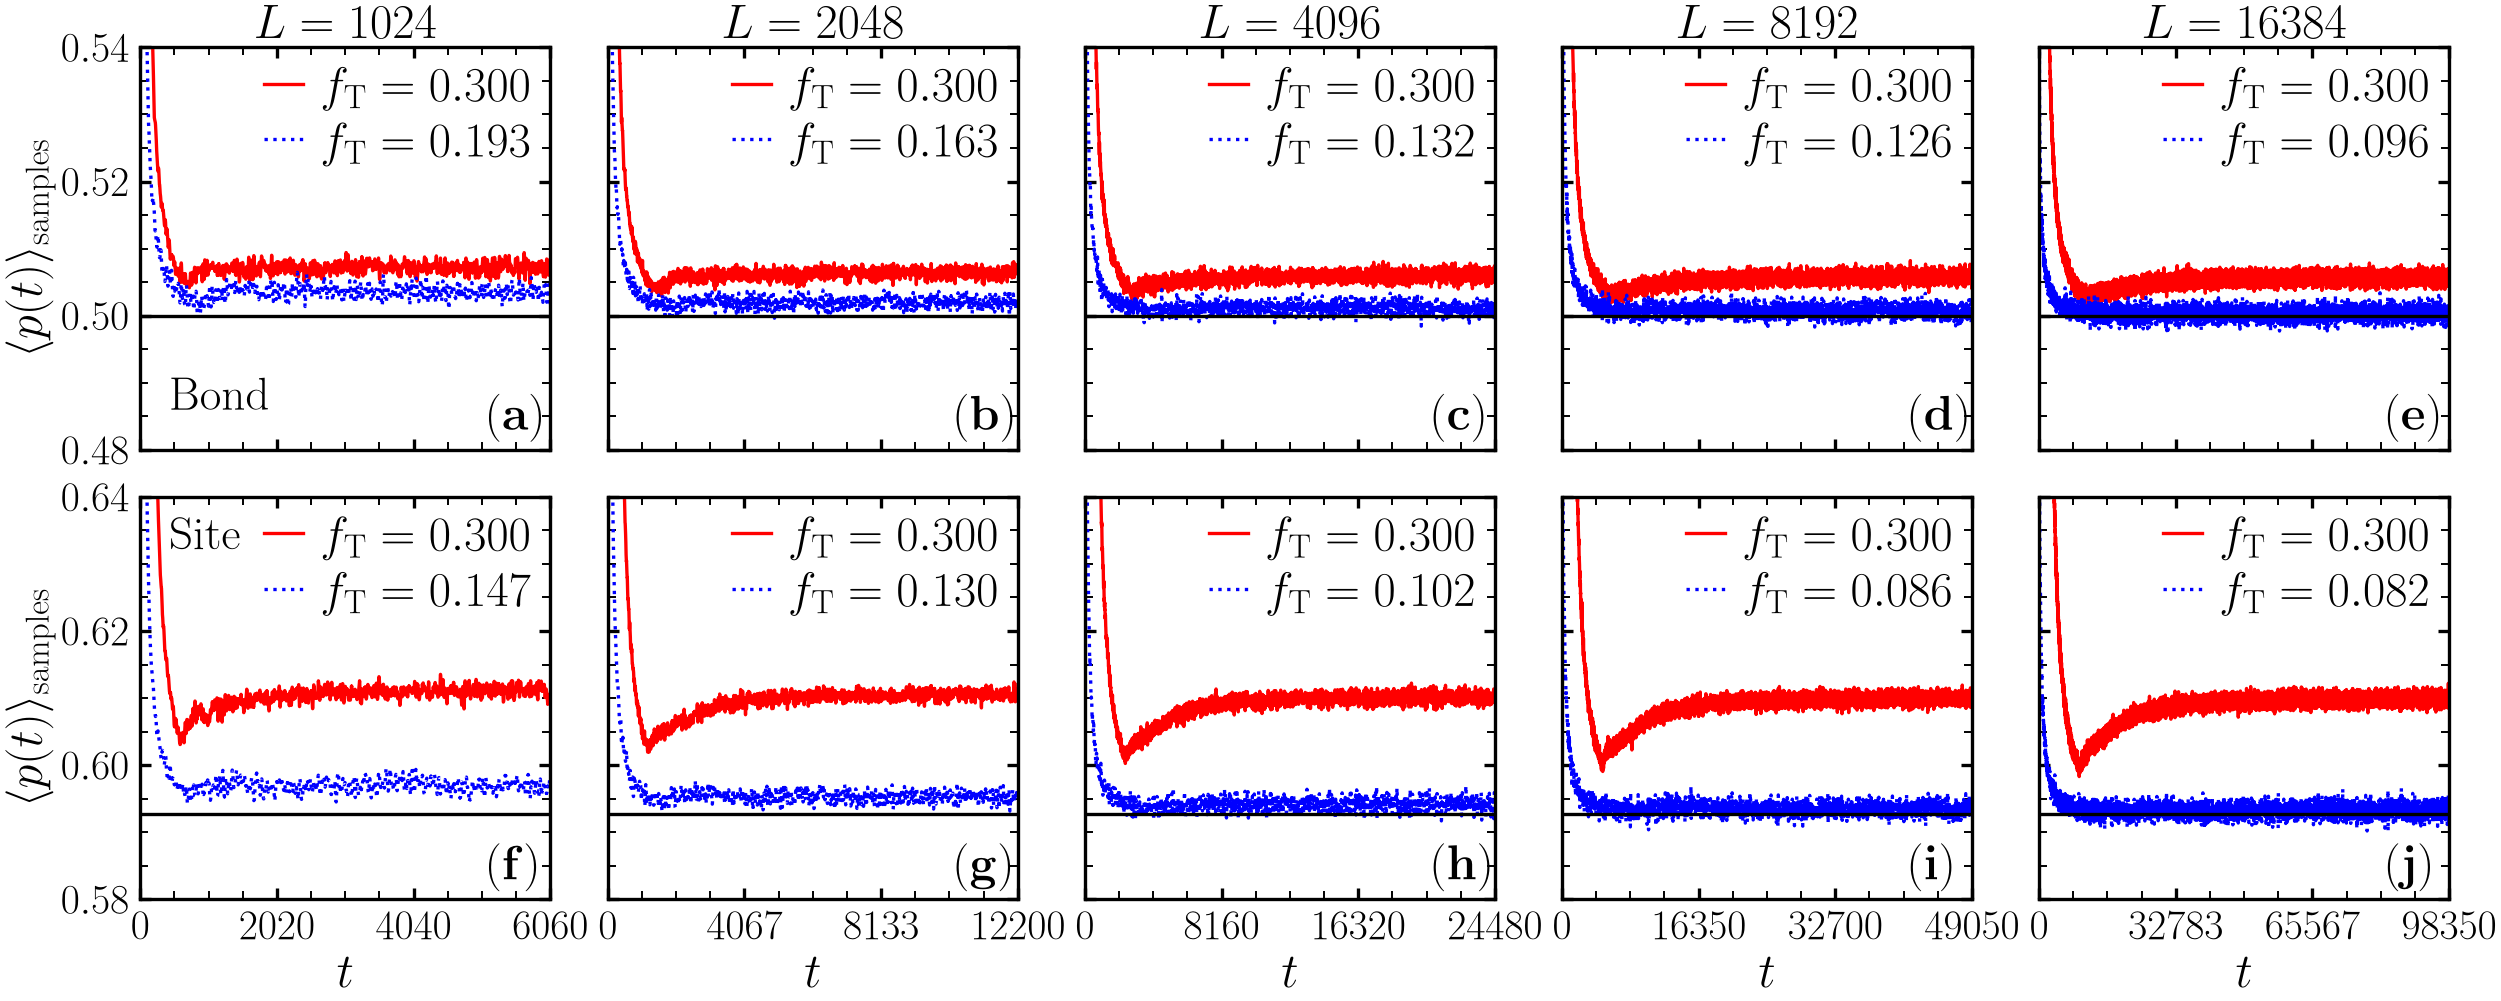

In [10]:
nc = 1
dim = 2
c = 0.1
rho = 1 / nc

L_lst = [1024, 2048, 4096, 8192, 16384]
modes = ["bond", "node"]

base = 5
n_rows = len(modes)
n_columns = len(L_lst)

fs_title = 35
fs_label = 35
fs_legend = 35
fs_ticks = 30
fs_mode_fig = 34
fs_subplots = 35

p0 = 0.8
P0 = 0.2
rule_update = 'linear'

fig, axes = plt.subplots(
    n_rows,
    n_columns,
    figsize=(n_columns * base, n_rows * base),
    constrained_layout=True,
    sharey='row',
    sharex='col'
)

labels_sub = [
    r"$\mathbf{(a)}$", r"$\mathbf{(b)}$",
    r"$\mathbf{(c)}$", r"$\mathbf{(d)}$",
    r"$\mathbf{(e)}$", r"$\mathbf{(f)}$",
    r"$\mathbf{(g)}$", r"$\mathbf{(h)}$",
    r"$\mathbf{(i)}$", r"$\mathbf{(j)}$"
]

t_max_by_col = np.full(n_columns, np.inf)
colors = ['r','b']
ls = ['solid', 'dotted']
for idx_mode, mode in enumerate(modes):
    for idx_L, L in enumerate(L_lst):
        ax = axes[idx_mode, idx_L]

        df_ft = df_min_bond if mode == "bond" else df_min_node
        row_ft = df_ft[
            np.isclose(df_ft["c"].astype(float), c)
            & (df_ft["L"].astype(int) == L)
            & (df_ft["nc"].astype(int) == nc)
        ]
        if row_ft.empty:
            print(f"No f_T limits for mode={mode}, L={L}, c={c}, nc={nc}")
            continue

        ft_min = row_ft["f_T_min"].iloc[0]
        ft_max = row_ft["f_T_max"].iloc[0]
        ft_lst = [ft_max, ft_min]

        for idx_color, ft in enumerate(ft_lst):
            if not np.isfinite(ft):
                print(f"Invalid f_T for mode={mode}, L={L}: {ft}")
                continue

            fn = (
                f"../SOP_data/published_dynamic/"
                f"{mode}_percolation/"
                f"num_colors_{nc}/dim_{dim}/L_{L}/"
                f"fT_constant/fT_{ft:.6e}/"
                f"c_{c:.6e}/rho_{rho:.4e}/"
                f"properties_dynamic_bundle.json.xz"
            )
            try:
                bundle = read_dynamic_bundle(fn)
                row = select_dynamic_bundle_row(bundle, p0=p0, P0=P0, order=0, rule_update=rule_update)
                t, p_t, source = dynamic_series_from_row(row, observable="pt")

                ax.plot(
                    t,
                    p_t,
                    ls=ls[idx_color],
                    color=colors[idx_color],
                    lw=2.4,
                    label=fr"$f_\mathrm{{T}}={ft:.3f}$"
                )

                t_max_by_col[idx_L] = min(t_max_by_col[idx_L], np.nanmax(t))

            except FileNotFoundError:
                print(f"File does not exist: mode={mode}, L={L}, f_T={ft}")
                continue
            except ValueError as exc:
                print(f"Cannot plot mode={mode}, L={L}, f_T={ft}: {exc}")
                continue
    
        if idx_L == 0:
            ax.set_ylabel(
                r"$\langle p(t) \rangle_{\mathrm{samples}}$",
                fontsize=fs_label
            )

        if idx_mode == n_rows - 1:
            ax.set_xlabel(r"$t$", fontsize=fs_label)
            
        ax.legend(frameon=False, fontsize=fs_legend)
        ax.tick_params(axis="both", width=2.4, length=8, pad=8, labelsize=fs_ticks)

        if idx_mode == 0:
            ax.set_title(fr"$L={L}$", fontsize=fs_title)

            ax.set_ylim(0.48, 0.54)
            ax.set_yticks([0.48, 0.50, 0.52, 0.54])
            ax.axhline(y=0.5, color="k", lw=2.4)

            pos = [0.84, 0.05]

            if idx_L == 0:
                ax.text(
                    0.07,
                    0.10,
                    "Bond",
                    transform=ax.transAxes,
                    fontsize=fs_mode_fig,
                )

        elif idx_mode == 1:
            ax.set_ylim(0.58, 0.64)
            ax.set_yticks([0.58, 0.60, 0.62, 0.64])
            ax.axhline(y=0.59274605079016, color="k", lw=2.4)

            pos = [0.84, 0.05]

            if idx_L == 0:
                ax.text(
                    0.07,
                    0.87,
                    "Site",
                    transform=ax.transAxes,
                    fontsize=fs_mode_fig,
                )

        for spine in ax.spines.values():
            spine.set_linewidth(2.4)

        count = idx_mode * len(L_lst) + idx_L

        ax.text(
            pos[0],
            pos[1],
            s=labels_sub[count],
            transform=ax.transAxes,
            fontsize=fs_subplots,
            fontweight="bold",
        )
        ax.xaxis.set_major_locator(LinearLocator(numticks=4))

for idx_L, t_max in enumerate(t_max_by_col):
    if np.isfinite(t_max) and t_max > 0:
        for idx_mode in range(n_rows):
            axes[idx_mode, idx_L].set_xlim(0, t_max)

plt.savefig(f"{results_folder}/multiFT_L.pdf", dpi=300)
plt.show()


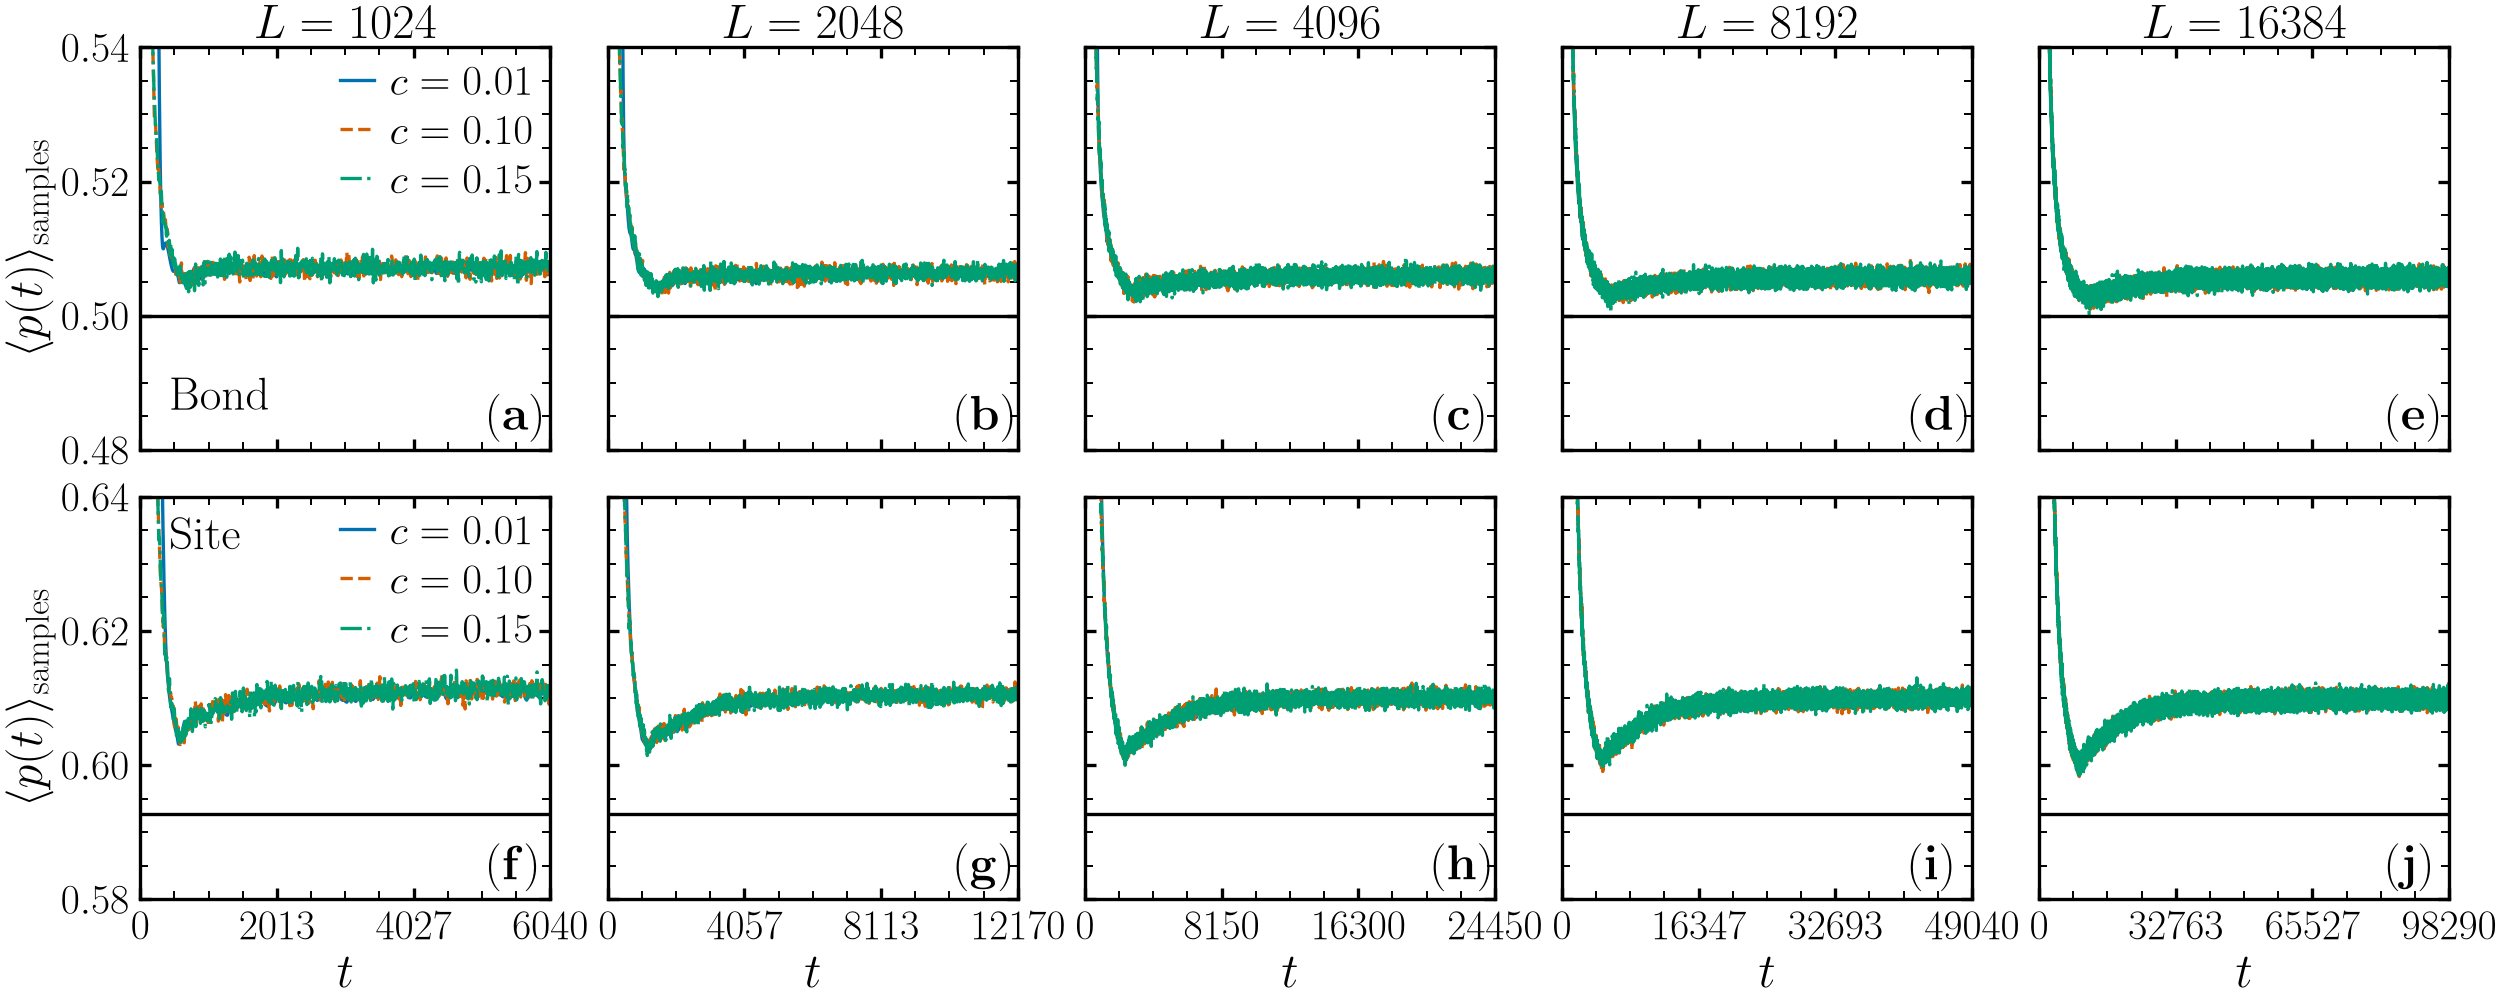

In [11]:
nc = 1
dim = 2
c = 0.1
rho = 1 / nc
ft = 0.3
L_lst = [1024, 2048, 4096, 8192, 16384]
modes = ["bond", "node"]

base = 5
n_rows = len(modes)
n_columns = len(L_lst)

fs_title = 35
fs_label = 35
fs_legend = 31
fs_ticks = 30
fs_mode_fig = 34
fs_subplots = 35

p0 = 0.8
P0 = 0.2
rule_update = 'linear'
c_lst = [0.01, 0.1, 0.15]
fig, axes = plt.subplots(
    n_rows,
    n_columns,
    figsize=(n_columns * base, n_rows * base),
    constrained_layout=True,
    sharey='row',
    sharex='col'
)

labels_sub = [
    r"$\mathbf{(a)}$", r"$\mathbf{(b)}$",
    r"$\mathbf{(c)}$", r"$\mathbf{(d)}$",
    r"$\mathbf{(e)}$", r"$\mathbf{(f)}$",
    r"$\mathbf{(g)}$", r"$\mathbf{(h)}$",
    r"$\mathbf{(i)}$", r"$\mathbf{(j)}$"
]

t_max_by_col = np.full(n_columns, np.inf)

colors = [
    "#0072B2",  # blue
    "#D55E00",  # vermillion
    "#009E73",  # bluish green
    "#CC79A7",  # reddish purple
]
ls = ['-', '--', '-.', ':']

for idx_mode, mode in enumerate(modes):
    for idx_L, L in enumerate(L_lst):
        ax = axes[idx_mode, idx_L]

        df_ft = df_min_bond if mode == "bond" else df_min_node
        row_ft = df_ft[
            np.isclose(df_ft["c"].astype(float), c)
            & (df_ft["L"].astype(int) == L)
            & (df_ft["nc"].astype(int) == nc)
        ]
        if row_ft.empty:
            print(f"No f_T limits for mode={mode}, L={L}, c={c}, nc={nc}")
            continue

        for idx_color, c_value in enumerate(c_lst):
            if not np.isfinite(ft):
                print(f"Invalid f_T for mode={mode}, L={L}: {ft}")
                continue

            fn = (
                f"../SOP_data/published_dynamic/"
                f"{mode}_percolation/"
                f"num_colors_{nc}/dim_{dim}/L_{L}/"
                f"fT_constant/fT_{ft:.6e}/"
                f"c_{c_value:.6e}/rho_{rho:.4e}/"
                f"properties_dynamic_bundle.json.xz"
            )
            try:
                bundle = read_dynamic_bundle(fn)
                row = select_dynamic_bundle_row(bundle, p0=p0, P0=P0, order=0, rule_update=rule_update)
                t, p_t, source = dynamic_series_from_row(row, observable="pt")

                ax.plot(
                    t,
                    p_t,
                    ls=ls[idx_color],
                    color=colors[idx_color],
                    lw=2.4,
                    label=fr"$c={c_value:.2f}$"
                )

                t_max_by_col[idx_L] = min(t_max_by_col[idx_L], np.nanmax(t))

            except FileNotFoundError:
                print(f"File does not exist: mode={mode}, L={L}, c={c_value}")
                continue
            except ValueError as exc:
                print(f"Cannot plot mode={mode}, L={L}, c={c_value}: {exc}")
                continue
    
        if idx_L == 0:
            ax.set_ylabel(
                r"$\langle p(t) \rangle_{\mathrm{samples}}$",
                fontsize=fs_label
            )

        if idx_mode == n_rows - 1:
            ax.set_xlabel(r"$t$", fontsize=fs_label)
            
        
        ax.tick_params(axis="both", width=2.4, length=8, pad=8, labelsize=fs_ticks)

        if idx_mode == 0:
            ax.set_title(fr"$L={L}$", fontsize=fs_title)

            ax.set_ylim(0.48, 0.54)
            ax.set_yticks([0.48, 0.50, 0.52, 0.54])
            ax.axhline(y=0.5, color="k", lw=2.4)

            pos = [0.84, 0.05]

            if idx_L == 0:
                ax.text(
                    0.07,
                    0.10,
                    "Bond",
                    transform=ax.transAxes,
                    fontsize=fs_mode_fig,
                )
                ax.legend(frameon=False, fontsize=fs_legend)
        elif idx_mode == 1:
            ax.set_ylim(0.58, 0.64)
            ax.set_yticks([0.58, 0.60, 0.62, 0.64])
            ax.axhline(y=0.59274605079016, color="k", lw=2.4)

            pos = [0.84, 0.05]

            if idx_L == 0:
                ax.text(
                    0.07,
                    0.87,
                    "Site",
                    transform=ax.transAxes,
                    fontsize=fs_mode_fig,
                )
                ax.legend(frameon=False, fontsize=fs_legend)
        for spine in ax.spines.values():
            spine.set_linewidth(2.4)

        count = idx_mode * len(L_lst) + idx_L

        ax.text(
            pos[0],
            pos[1],
            s=labels_sub[count],
            transform=ax.transAxes,
            fontsize=fs_subplots,
            fontweight="bold",
        )
        ax.xaxis.set_major_locator(LinearLocator(numticks=4))

for idx_L, t_max in enumerate(t_max_by_col):
    if np.isfinite(t_max) and t_max > 0:
        for idx_mode in range(n_rows):
            axes[idx_mode, idx_L].set_xlim(0, t_max)

plt.savefig(f"{results_folder}/multiC_L.pdf", dpi=300)
plt.show()


In [10]:
df_dynamic = pd.read_csv("../SOP_data/all_colors_dynamic.dat", sep=' ')
df_dynamic

,type_perc,dim,L,f_T,c,num_colors,P0,p0,control_rule,N_samples,rho,nc,nc_err,nc_std,stat_window,stop_criterion,t_eq_validation,t_eq_s_prime_threshold,equilibrium_effective_rel_tol,post_equilibrium_extra_steps
0,bond,2,512,0.01,0.01,1,0.2,0.8,linear,702,1,0.0,0.0,0.0,0,NaN,NaN,NaN,NaN,NaN
1,bond,2,512,0.01,0.01,1,0.2,0.8,relative,702,1,0.0,0.0,0.0,0,NaN,NaN,NaN,NaN,NaN
2,bond,2,512,0.01,0.01,1,0.8,0.8,relative,702,1,0.0,0.0,0.0,0,NaN,NaN,NaN,NaN,NaN
3,bond,2,1024,0.01,0.01,1,0.2,0.8,linear,502,1,0.0,0.0,0.0,0,NaN,NaN,NaN,NaN,NaN
4,bond,2,1024,0.01,0.01,1,0.2,0.8,relative,502,1,0.0,0.0,0.0,0,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7030,node,2,1024,0.30,0.15,1,0.2,0.8,linear,502,1,1.0,0.0,0.0,0,alive_species_pt_derivative_stability_or_death,global_tail_drift_validation_of_blocked_pt_var...,0.00001,0.025,100.0
7031,node,2,2048,0.30,0.15,1,0.2,0.8,linear,402,1,1.0,0.0,0.0,0,alive_species_pt_derivative_stability_or_death,global_tail_drift_validation_of_blocked_pt_var...,0.00001,0.025,100.0
7032,node,2,4096,0.30,0.15,1,0.2,0.8,linear,202,1,1.0,0.0,0.0,0,alive_species_pt_derivative_stability_or_death,global_tail_drift_validation_of_blocked_pt_var...,0.00001,0.025,100.0
7033,node,2,8192,0.30,0.15,1,0.2,0.8,linear,102,1,1.0,0.0,0.0,0,alive_species_pt_derivative_stability_or_death,global_tail_drift_validation_of_blocked_pt_var...,0.00001,0.025,100.0


In [11]:
control_rule = 'linear'  # use 'linear' para analisar a regra linear
df_series = pd.read_csv('../SOP_data/all_data_dynamic.dat', sep=r'\s+')
df_series

,type_perc,dim,L,f_T,c,nc,rho,p0,P0,control_rule,...,p_err,f_mean,f_err,z_stat_mean,z_stat_err,z_stat_median,z_stat_q75,z_stat_q90,t_eq_validation,t_eq_s_prime_threshold
0,bond,2,4096,0.020000,0.01,1,1,0.8,0.02,relative,...,0.000376,0.020000,3.305353e-07,4096.500000,0.500000,4096.5,4096.75,4096.9,global_tail_drift_validation_of_blocked_pt_var...,0.00001
1,bond,2,2048,0.025263,0.01,1,1,0.8,0.80,relative,...,0.000000,0.025250,0.000000e+00,2050.000000,0.000000,2050.0,2050.00,2050.0,NaN,NaN
2,bond,2,4096,0.025263,0.01,1,1,0.8,0.20,relative,...,0.000261,0.025264,3.673398e-06,4100.200000,1.157584,4101.0,4102.00,4102.6,NaN,NaN
3,bond,2,4096,0.025263,0.01,1,1,0.8,0.80,relative,...,0.000376,0.025269,1.266400e-05,4098.750000,1.314978,4099.0,4101.00,4101.0,NaN,NaN
4,bond,2,8192,0.025263,0.01,1,1,0.8,0.20,linear,...,0.000097,0.025257,4.488178e-06,8195.571429,0.922139,8196.0,8197.00,8197.8,global_tail_drift_validation_of_blocked_pt_var...,0.00001
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6521,node,2,1024,0.300000,0.15,1,1,0.8,0.20,linear,...,0.000038,0.300015,1.256338e-06,1026.922311,0.094120,1027.0,1029.00,1030.0,global_tail_drift_validation_of_blocked_pt_var...,0.00001
6522,node,2,2048,0.300000,0.15,1,1,0.8,0.20,linear,...,0.000025,0.300013,4.951320e-07,2050.562189,0.100276,2050.0,2052.00,2053.0,global_tail_drift_validation_of_blocked_pt_var...,0.00001
6523,node,2,4096,0.300000,0.15,1,1,0.8,0.20,linear,...,0.000020,0.300010,2.711507e-07,4098.643564,0.142661,4099.0,4100.00,4102.0,global_tail_drift_validation_of_blocked_pt_var...,0.00001
6524,node,2,8192,0.300000,0.15,1,1,0.8,0.20,linear,...,0.000016,0.300008,1.239912e-07,8194.568627,0.209236,8194.0,8196.00,8198.0,global_tail_drift_validation_of_blocked_pt_var...,0.00001


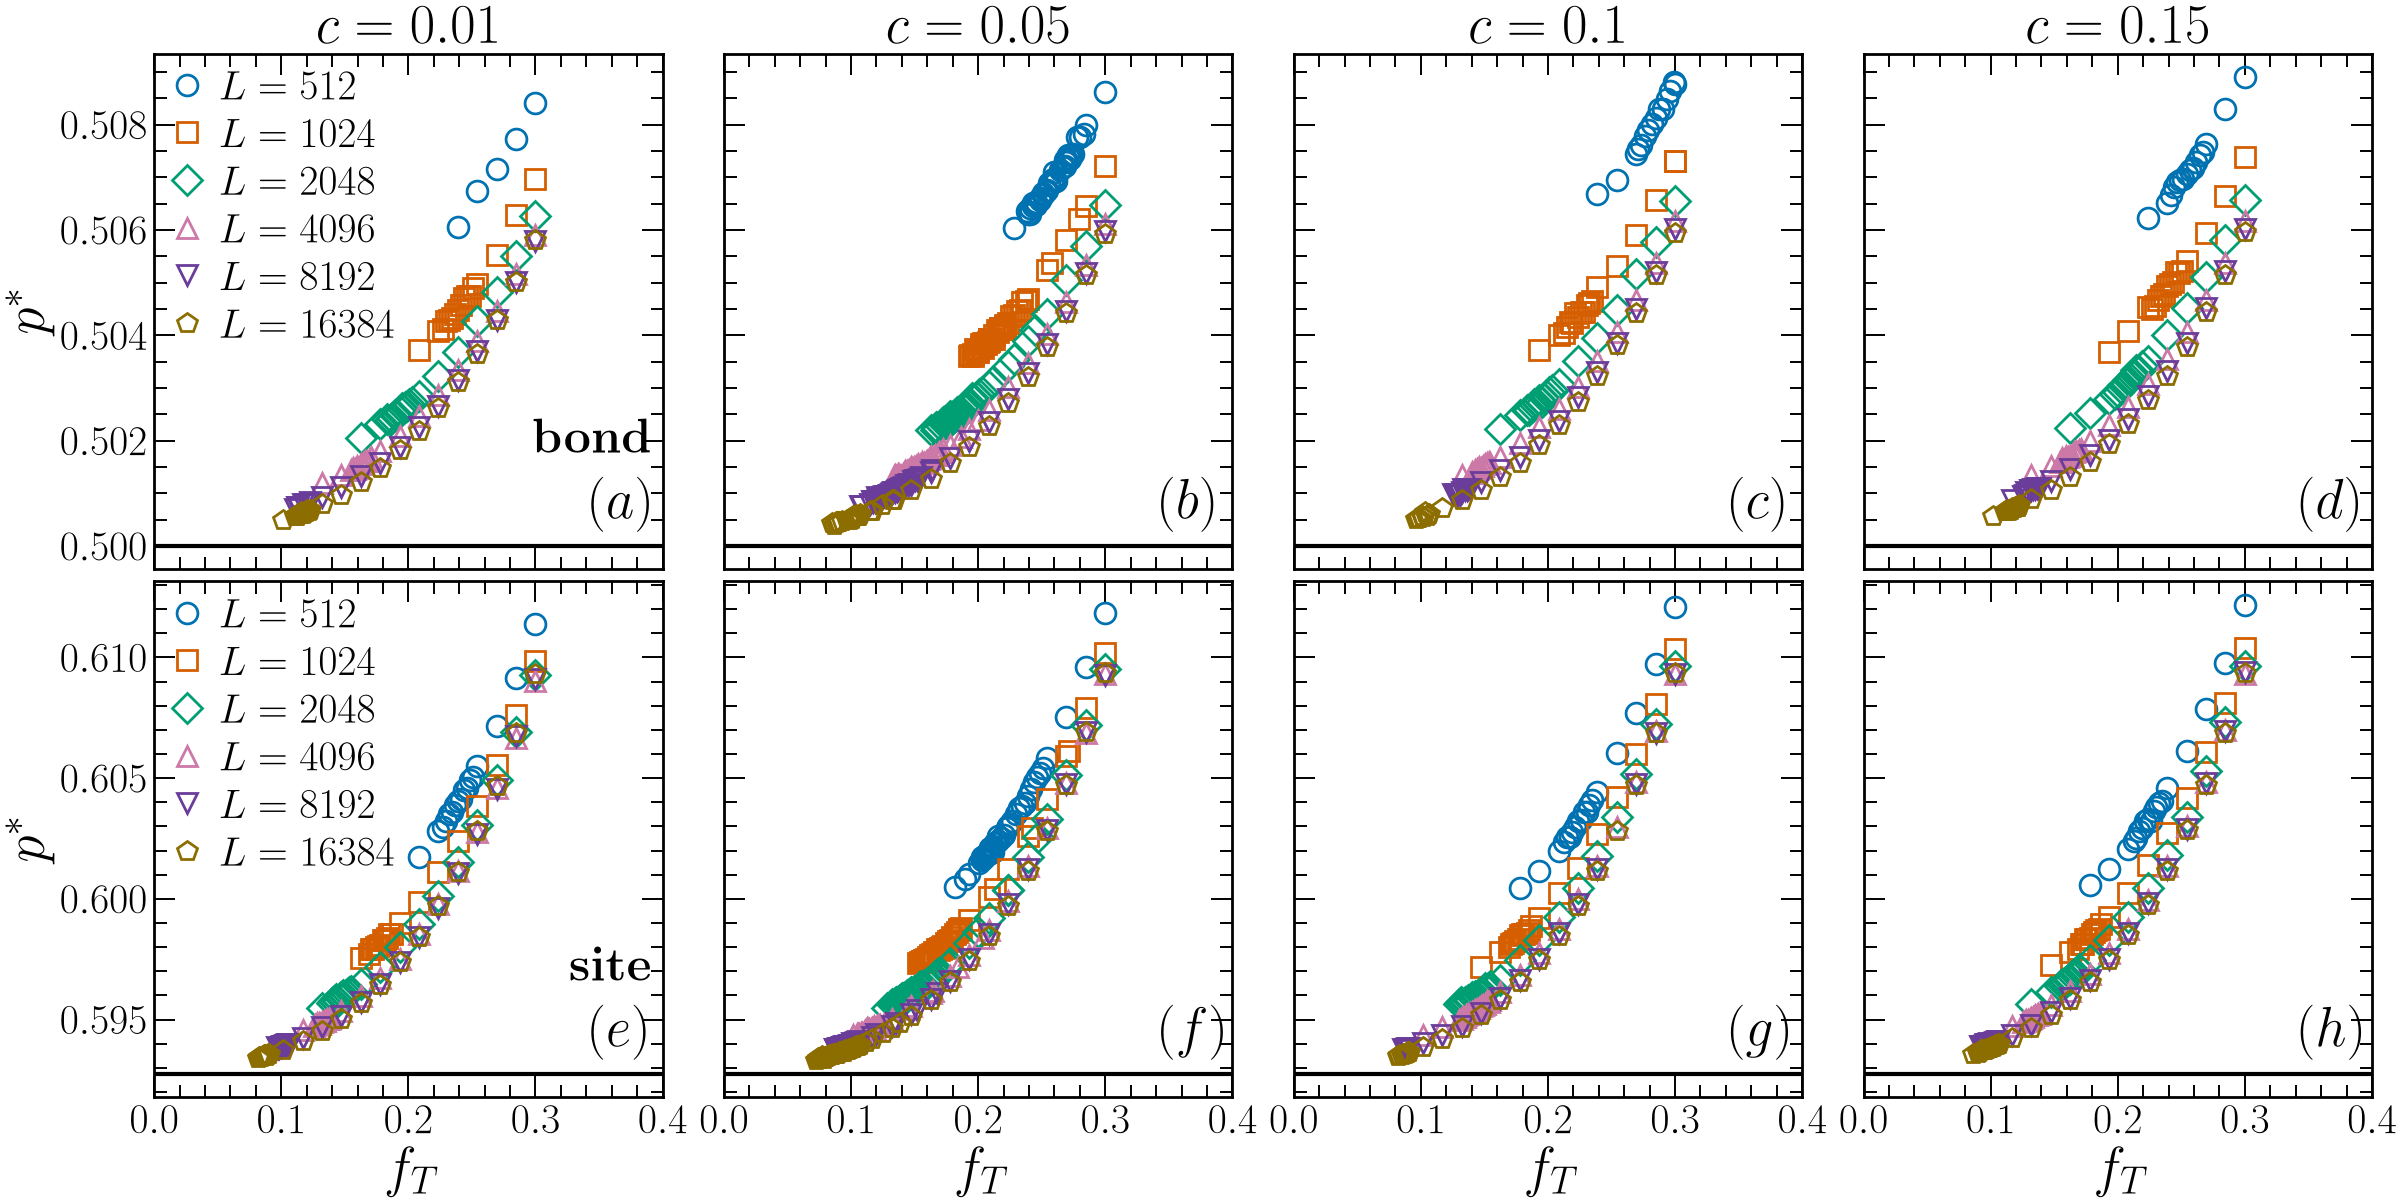

In [12]:
L_lst = [512, 1024, 2048, 4096, 8192, 16384]

nc = 1
rho = 1 / nc
order = 0
p0 = 0.8
dim = 2

middle_points = []

markers = ['o', 's', 'D', '^', 'v', 'p']

colors = [
    "#0072B2",  # azul
    "#D55E00",  # laranja avermelhado
    "#009E73",  # verde
    "#CC79A7",  # magenta
    "#6A3D9A",  # roxo
    "#8C6D00",  # amarelo-ouro escuro
]

base = 6
c_lst = [0.01, 0.05, 0.10, 0.15]

fs_l_fig = 40
fs_label = 40
control_rule = 'linear'
# Nome apresentado na figura
type_perc_lst = ['bond', 'site']

# Limiares de percolação para a rede quadrada 2D:
# bond -> 0.5
# site/node -> aproximadamente 0.592746
pc_dict = {
    'bond': 0.5,
    'site': 0.59274605079016
}

labels = [
    r"$(a)$", r"$(b)$", r"$(c)$", r"$(d)$",
    r"$(e)$", r"$(f)$", r"$(g)$", r"$(h)$"
]

fig, axes = plt.subplots(
    2,
    4,
    figsize=(4 * base, 2 * base),
    constrained_layout=True,
    sharex=True,
    sharey='row'
)
P0 = 0.2
aux = []

for idx_type, type_perc in enumerate(type_perc_lst):

    # No DataFrame, percolação por sítio está armazenada como "node"
    type_perc_df = type_perc

    if type_perc == 'site':
        type_perc_df = 'node'

    pc = pc_dict[type_perc]

    for idx_c, c in enumerate(c_lst):

        ax = axes[idx_type, idx_c]
        idx_panel = idx_type * len(c_lst) + idx_c

        for idx_L, L in enumerate(L_lst):

            df_SUB = df_series[
                (df_series['type_perc'] == type_perc_df)
                & (df_series['p0'] == p0)
                & (df_series['order'] == order)
                & (df_series['nc'] == nc)
                & (df_series['L'] == L)
                & (df_series['c'] == c)
                & (df_series['dim'] == dim)
                & (df_series['P0'] == P0)
                & (df_series['control_rule'] == control_rule)
            ].sort_values(
                by='f_T'
            ).reset_index(drop=True)

            df_filter = df_SUB[
                (0.98 * df_SUB['N_samples'])
                <= df_SUB['N_samples_perc']
            ]

            df_plot = df_filter.sort_values('f_T').copy()

            df_plot = df_plot[
                (df_plot['p_mean'] >= 0)
                & (df_plot['p_mean'] <= 1)
            ]

            df_plot = df_plot[
                df_plot['N_samples_perc'] >= 5
            ]

            # Remove o regime saturado
            df_plot = df_plot[
                df_plot['p_mean'] < 0.9
            ]

            df_trunc = df_plot[
                df_plot['f_T'] <= 0.4
            ].copy()

            x = df_trunc['f_T']
            y = df_trunc['p_mean']

            if len(x) > 0:
                row_ft_min = df_trunc.loc[
                    df_trunc['f_T'].idxmin()
                ]

                aux.append(
                    (
                        row_ft_min['f_T'],
                        L,
                        c,
                        idx_type
                    )
                )

                # print(
                #     type_perc,
                #     row_ft_min['f_T'],
                #     L,
                #     c,
                #     row_ft_min['N_samples'],
                #     row_ft_min['N_samples_perc']
                # )

            ax.plot(
                x,
                y,
                markers[idx_L],
                ms=15,
                mew=2.0,
                color=colors[idx_L],
                label=fr'$L={L}$'
            )
        if idx_c == 0:
            ax.annotate(
                fr'$\mathbf{{{type_perc}}}$',
                xy=(1.0, 0.25),
                xycoords='axes fraction',
                xytext=(-8, 0),
                textcoords='offset points',
                ha='right',
                va='center',
                fontsize=35
            )

        ax.text(
            0.85,
            0.10,
            f'{labels[idx_panel]}',
            transform=ax.transAxes,
            fontsize=fs_l_fig
        )
        ax.axhline(
            y=pc,
            color='k',
            linestyle='-',
            linewidth=3.0

        )
        if(type_perc=='bond'):
            ax.set_title(f'$c = {c}$',fontsize=40)
        ax.set_xlim(0.0, 0.4)
        ax.tick_params(axis="both", which="major", width=1.4, length=15, labelsize=30)
        ax.tick_params(axis="both", which="minor", width=1.4, length=9, labelsize=30)

# Legenda apenas nos painéis da primeira coluna
for ax in axes[:, 0]:
    ax.legend(loc='best',fontsize=30
              )
    ax.set_ylabel(r"$p^*$", fontsize=fs_label)

# Eixo x apenas na linha inferior
for ax in axes[1, :]:
    ax.set_xlabel(r"$f_T$", fontsize=fs_label)
plt.savefig(results_folder + f"/pstar_vs_ft_2D.pdf")
plt.show()

vec = np.array(aux, dtype=float)

if len(vec) > 0:
    # Ordena primeiro pelo tipo, depois por c e por L
    index = np.lexsort((vec[:, 1], vec[:, 2], vec[:, 3]))
    triplas_ordenadas = vec[index]

    np.set_printoptions(suppress=True)
    # print(triplas_ordenadas)